# 06 · Volatility regimes — filtered, never smoothed

Conditioning on a latent vol state is only honest if the state at t uses no future data. Three
leaks are closed: no smoothed `predict_proba` (hand forward filter, AST-guarded, provably
invariant under truncation), EM fit on TRAIN only, and causal trailing standardisation.

In [1]:
%load_ext autoreload
%autoreload 2
import datetime as dt, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fxpd.config import TRIANGLES, OUTPUTS_DIR, ensure_dirs
from fxpd.calendar.sessions import label_sessions
from fxpd.data.processed import get_panel
from fxpd.vol import realized as rz
from fxpd.regimes import hmm as H
from fxpd.econo import discovery as disc
from fxpd.inference import bootstrap as bs
ensure_dirs(); warnings.simplefilter("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## Parameters + pre-registered hypotheses (before any result)

Priors: stressed periods should error-correct faster (arb capital chases vol); the share may or
may not move. Statistic = nanmedian(stressed) − nanmedian(calm), Holm across the family.

- V1: GG_cross(stressed) − GG_cross(calm) ≠ 0
- V2: half-life(stressed) − half-life(calm) < 0

Confounder (from Week 5): stressed = more ticks = fresher, and fresher bars mechanically
error-correct faster — exactly V2's prediction. So V1/V2 are also run fresh-only.

In [2]:
TRIANGLE="majors"
START, END = dt.date(2025,12,15), dt.date(2026,7,20)
K, LIQUID, MIN_BARS = 10, (7,17), 500
TRAIN_FRAC = 0.60
tri = TRIANGLES[TRIANGLE]
dates = list(pd.bdate_range(START, END).date)
print(f"{tri} | {len(dates)} days | 30-min RK blocks in liquid hours | TRAIN {TRAIN_FRAC:.0%}")

Triangle(name='majors', cross='EURJPY', leg1='EURUSD', leg2='USDJPY') | 156 days | 30-min RK blocks in liquid hours | TRAIN 60%


## 1 · Realized kernel + the honest diagnostic

dropped 18 non-positive RK blocks (invalid vol estimates); kept 3082
RK diag: {'n_blocks': 3082, 'omega2_zero_share': 0.41, 'H_median': 3.0, 'rk_over_rv_median': 0.991} | gate: {'block_share_in_band': 0.576, 'day_share_in_band': 0.942, 'n_days': 155}


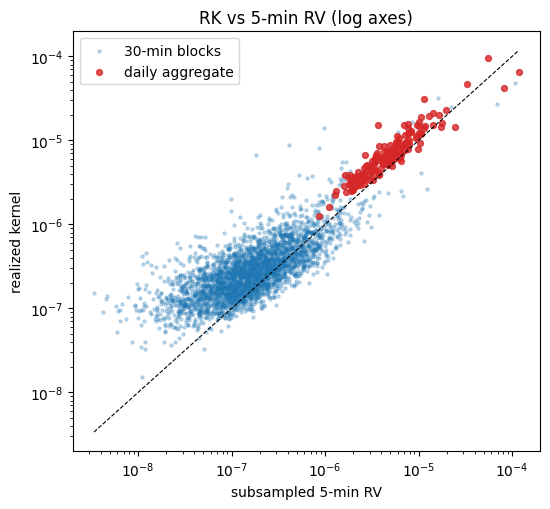

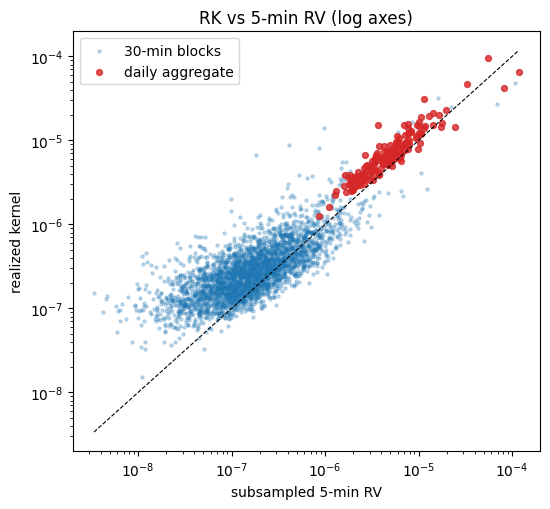

In [3]:
B = rz.rk_blocks(tri, dates, liquid=LIQUID)
print(f"dropped {B.attrs.get('dropped_nonpositive_rk',0)} non-positive RK blocks "
      f"(invalid vol estimates); kept {len(B)}")
diag = rz.rk_diagnostics(B); gate = rz.sanity_gate(B)
print("RK diag:", {k: round(v,3) for k,v in diag.items()}, "| gate:", {k: round(v,3) for k,v in gate.items()})
fig, ax = plt.subplots(figsize=(5.6,5.2))
ax.scatter(B.rv_5min, B.rk, s=5, alpha=0.25, label="30-min blocks")
d = B.groupby("date")[["rk","rv_5min"]].sum()
ax.scatter(d.rv_5min, d.rk, s=18, color="tab:red", alpha=0.8, label="daily aggregate")
lim=[min(B.rv_5min.min(), d.rv_5min.min()), max(B.rv_5min.max(), d.rv_5min.max())]
ax.plot(lim, lim, "k--", lw=0.8); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("subsampled 5-min RV"); ax.set_ylabel("realized kernel"); ax.legend()
ax.set_title("RK vs 5-min RV (log axes)")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"06_rk_sanity.png", dpi=130); fig

## 2 · TRAIN/EVAL split, EM fit, and the filtered state

blocks 2832 (after trailing-window warmup) | TRAIN 1789 | EVAL 1043
EVAL state mix: {'calm': 688, 'stressed': 260, 'uncertain': 95} | uncertain (excluded) = 9.1%


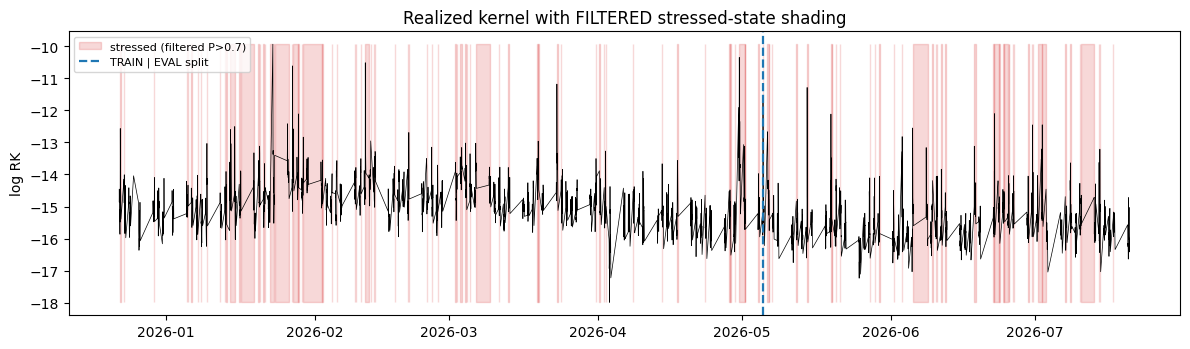

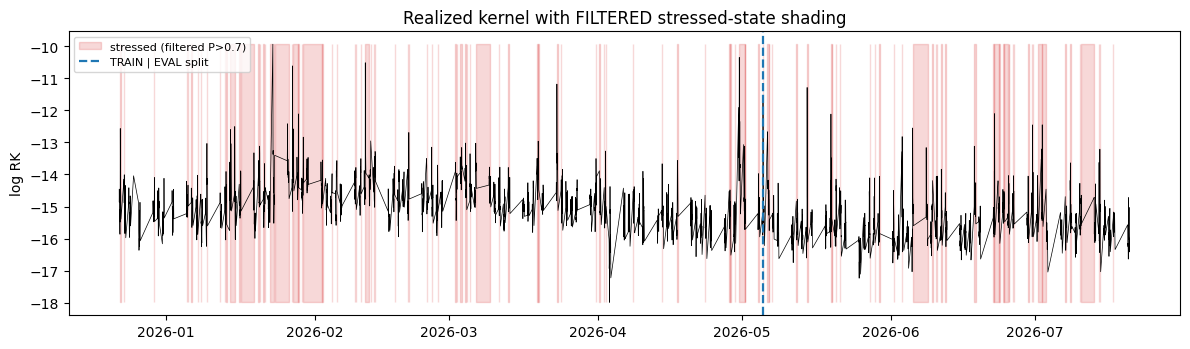

In [4]:
x_raw = np.log(B.rk).to_numpy()
xs_all = H.rolling_standardise(x_raw, window=400, min_periods=100)
ok = np.isfinite(xs_all)
B = B[ok].reset_index(drop=True); xs = xs_all[ok]
cut = int(TRAIN_FRAC*len(B))
len_tr = list(B.iloc[:cut].groupby("date").size().to_numpy())
lengths = list(B.groupby("date").size().to_numpy())
model = H.fit_hmm(xs[:cut], len_tr, seed=0)
sp, tm, mu, var = H.hmm_params(model)
p_str = H.filtered_by_segment(xs, lengths, sp, tm, mu, var)[:, H.stressed_index(mu)]
B = B.assign(p_stressed=p_str, state=H.label_states(p_str))
B["state"] = H.lag_state_within_day(B["state"].to_numpy(), B["date"].to_numpy())
B = B.dropna(subset=["state"]).reset_index(drop=True)
EVAL = B.iloc[cut:].copy()
print(f"blocks {len(B)} (after trailing-window warmup) | TRAIN {cut} | EVAL {len(EVAL)}")
print("EVAL state mix:", EVAL.state.value_counts().to_dict(),
      f"| uncertain (excluded) = {(EVAL.state=='uncertain').mean():.1%}")

fig, ax = plt.subplots(figsize=(12,3.6))
t = pd.DatetimeIndex(B.block)
ax.plot(t, np.log(B.rk), lw=0.5, color="k")
ax.fill_between(t, np.log(B.rk).min(), np.log(B.rk).max(), where=(B.state=="stressed").to_numpy(),
                color="tab:red", alpha=0.18, step="mid", label="stressed (filtered P>0.7)")
ax.axvline(t[cut], color="tab:blue", lw=1.6, ls="--", label="TRAIN | EVAL split")
ax.set_ylabel("log RK"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Realized kernel with FILTERED stressed-state shading")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR/"06_rk_states.png", dpi=130); fig

## 3 · Lookahead ledger — exactly what was fit on what

In [5]:
ledger = H.lookahead_ledger(cut, len(EVAL),
    "causal trailing z-score of log RK (window=400 blocks, stats shifted 1 -> uses only the past)",
    model)
for k,v in ledger.items(): print(f"  {k}: {v}")

  blocks_train (EM fit here): 1789
  blocks_eval (ALL reported results here): 1043
  standardisation: causal trailing z-score of log RK (window=400 blocks, stats shifted 1 -> uses only the past)
  fitted_means (standardised): [0.9861, -0.5225]
  fitted_sds: [0.9236, 0.7126]
  stressed_state_index: 0
  posterior_used: FILTERED (hand forward filter) -- predict_proba never called


## 4 · Confounder controls: state × session, and freshness by state

In [6]:
EVAL = EVAL.assign(session=[str(s) for s in label_sessions(pd.DatetimeIndex(EVAL.block))])
ct = pd.crosstab(EVAL.session, EVAL.state)
display(ct)

rows=[]
for d in sorted(set(EVAL.date))[::4]:
    try: pan = get_panel(tri, d, "1s")
    except FileNotFoundError: continue
    day = EVAL[EVAL.date==d]
    for s in ["stressed","calm"]:
        blk = pd.DatetimeIndex(day[day.state==s].block)
        if len(blk)==0: continue
        m = pd.Series(True, index=blk).reindex(pan.index, method="ffill",
                     tolerance=pd.Timedelta("30min")).fillna(False).astype(bool)
        w = pan[m.to_numpy()]
        if len(w)==0: continue
        rows.append({"state":s,
                     "synth_fresh":float(((w[f"age_{tri.leg1}"]<=1)&(w[f"age_{tri.leg2}"]<=1)).mean()),
                     "cross_fresh":float((w[f"age_{tri.cross}"]<=1).mean())})
FRESH = pd.DataFrame(rows).groupby("state").mean()
FRESH.round(3)

state,calm,stressed,uncertain
session,,,
LDN,248,58,24
LDN+NY,260,105,20
NY,99,50,16
TOK+LDN,81,47,35


,synth_fresh,cross_fresh
state,,
calm,0.28,0.683
stressed,0.333,0.762


## 5 · Regime-conditional discovery + V1/V2 (EVAL only)

In [7]:
def regime_res(stale=False, thr=None):
    src = B.iloc[cut:] if thr is None else B.iloc[cut:].assign(
        state=H.label_states(B.iloc[cut:].p_stressed.to_numpy(), hi=thr[0], lo=thr[1]))
    out={}
    for s in ["stressed","calm"]:
        bm = pd.Series((src.state==s).to_numpy(), index=pd.DatetimeIndex(src.block)).sort_index()
        out[s] = disc.fit_discovery_windows(tri, sorted(set(src.date)), "1s", K,
                                            bar_mask=bm, min_bars=MIN_BARS, stale_filter=stale)
    return out

res = regime_res()
TBL = pd.DataFrame({s: {
    "GG_cross": disc.aggregate_discovery(r).loc["cross","gg_median"],
    "GG [IQR]": f"[{disc.aggregate_discovery(r).loc['cross','gg_q25']:.2f}, {disc.aggregate_discovery(r).loc['cross','gg_q75']:.2f}]",
    "IS [lo, hi]": f"[{disc.aggregate_discovery(r).loc['cross','is_lo']:.2f}, {disc.aggregate_discovery(r).loc['cross','is_hi']:.2f}]",
    "HL_dynamic_s": round(disc.aggregate_discovery(r).attrs["half_life_dyn_median"],1),
    "n": disc.aggregate_discovery(r).attrs["n_valid"]} for s,r in res.items()}).T
display(TBL)

wide_gg = bs.metric_by_day(res, "gg_cross"); wide_hl = bs.metric_by_day(res, "half_life_dyn_s")
V = []
for name, wide, alt in [("V1 GG stressed!=calm", wide_gg, "two-sided"),
                        ("V2 HL stressed<calm",  wide_hl, "less")]:
    stat, ci, dist = bs.block_bootstrap(wide, bs.diff_medians("stressed","calm"),
                                        block=5, B=2000, seed=0)
    V.append({"hypothesis":name,"stat":stat,"ci_lo":ci[0],"ci_hi":ci[1],
              "p_raw":bs.p_from_dist(dist, alt)})
V = pd.DataFrame(V); V["p_holm"]=bs.holm(V["p_raw"].tolist())
V["verdict"]=np.where(V["p_holm"].isna(), "not computable",
                np.where(V["p_holm"]<0.05, "reject H0", "n.s."))
V.set_index("hypothesis").round(4)

,GG_cross,GG [IQR],"IS [lo, hi]",HL_dynamic_s,n
stressed,0.6395,"[0.46, 0.73]","[0.06, 0.97]",5.9,34
calm,0.6806,"[0.58, 0.73]","[0.09, 0.98]",7.7,50


,stat,ci_lo,ci_hi,p_raw,p_holm,verdict
hypothesis,,,,,,
V1 GG stressed!=calm,-0.041,-0.1322,0.029,0.337,0.337,n.s.
V2 HL stressed<calm,-1.851,-2.476,-0.3113,0.006,0.012,reject H0


## 6 · Robustness — staleness, thresholds, bandwidth

In [8]:
def gg_hl(r): 
    a=disc.aggregate_discovery(r); return a.loc["cross","gg_median"], a.attrs["half_life_dyn_median"]
res_sf = regime_res(stale=True)
res_thr = regime_res(thr=(0.8,0.2))
rob = pd.DataFrame({
    "GG (all bars)":      {s: gg_hl(res[s])[0]     for s in res},
    "GG (fresh only)":    {s: gg_hl(res_sf[s])[0]  for s in res_sf},
    "HL (all bars)":      {s: gg_hl(res[s])[1]     for s in res},
    "HL (fresh only)":    {s: gg_hl(res_sf[s])[1]  for s in res_sf},
    "GG (thr 0.8/0.2)":   {s: gg_hl(res_thr[s])[0] for s in res_thr},
})
display(rob.round(3))

bw = {f"H={h}": rz.rk_diagnostics(rz.rk_blocks(tri, dates[:40], liquid=LIQUID, H_override=h))["rk_over_rv_median"]
      for h in [1,3,6]}
print("\nbandwidth robustness (median RK/RV): ", {k: round(v,3) for k,v in bw.items()},
      "\n=> RK/RV barely moves with H, confirming the correction is inert on mids.")

bic = H.state_count_bic(xs[:cut], len_tr, ks=(1, 2, 3), seed=0)
print("\nstate-count BIC on TRAIN (lower is better):")
display(bic.round(1))
print(f"BIC-preferred K = {int(bic.loc[bic.bic.idxmin(), 'K'])}; "
      "two states are IMPOSED for interpretability, not selected")

,GG (all bars),GG (fresh only),HL (all bars),HL (fresh only),GG (thr 0.8/0.2)
stressed,0.64,0.583,5.889,4.413,0.573
calm,0.681,0.598,7.741,4.982,0.684



bandwidth robustness (median RK/RV):  {'H=1': 0.99, 'H=3': 0.985, 'H=6': 0.98} 
=> RK/RV barely moves with H, confirming the correction is inert on mids.



state-count BIC on TRAIN (lower is better):


,K,loglik,n_params,bic
0,1,-2584,2,5183
1,2,-2257,7,4566
2,3,-2080,14,4266


BIC-preferred K = 3; two states are IMPOSED for interpretability, not selected


## Takeaway

Share doesn't move with volatility; the speed effect is not clean.

- V1 (GG stressed vs calm): n.s. (−0.041, CI [−0.13, +0.03], Holm 0.34). The cross carries 0.64
  (stressed) / 0.68 (calm) on all bars, 0.58 / 0.60 fresh-only.
- V2 (half-life stressed < calm): −1.85 s, CI [−2.48, −0.31], Holm 0.012 — rejects on the grid,
  but fresh-only filtering shrinks the gap from 1.85 s to 0.57 s (5.9 vs 7.7 s → 4.4 vs 5.0 s),
  and stressed blocks are fresher (synth 33% vs 28%, cross 76% vs 68% of 1 s bars). Partly a
  freshness effect — not a clean structural result.
- Vol states aren't just sessions: every session holds both states (stressed share 18% in LDN to
  30% in NY).
- Two states are imposed, not selected: BIC prefers 3 (5183 / 4566 / 4266 for K = 1 / 2 / 3),
  though 2 beats 1 decisively.

Lookahead: filtered, never smoothed — the forward filter is truncation-invariant and predict_proba
is shown to fail the same check (tests/test_hmm.py); EM on TRAIN; causal trailing standardisation.
Caveats: on log-mid quotes the kernel noise correction is near-inert (ω²=0 in 41% of blocks,
RK/RV≈0.99); only 34 / 50 windows back V1 / V2.